# 03 — Citra dan footprint referensi

1. Citra Esri World Imagery zoom 19 (`raw/ui_rgb_esri_z19.tif`, EPSG:3857) → reproject ke UTM 0,3 m,
   clip AOI + 50 m → `interim/ui_rgb.tif` (8-bit, 3 band). Citra hanya untuk pendidikan; jangan didistribusikan ulang.
2. Layer OSM: gedung, jalan, air, vegetasi.
3. Bersihkan geometri: `make_valid`, explode multipolygon, buang < 10 m².
4. Google Open Buildings v3, confidence ≥ 0,75.
5. Verifikasi visual 25 gedung OSM di atas citra.

**Output**: `output/ref_buildings.gpkg`, `output/gob_buildings.gpkg`, `interim/osm_layers.gpkg`
(roads, water, vegetation), peta tematik (setara Fig. 5–6).

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Patch
from rasterio.plot import show
from rasterio.warp import Resampling, reproject

from ui3d_common import CATEGORY_COLORS, CFG, CRS, aoi, categorize, interim, out, raw, savefig

F = CFG["footprint"]
aoi_buf = aoi("aoi_buf50")
poly = aoi_buf.geometry.iloc[0]

## 1. Citra ke UTM 0,3 m

In [2]:
img_path = interim("ui_rgb.tif")
res = CFG["imagery"]["res_m"]
with rasterio.open(raw("imagery")) as src:
    # grid UTM yang dipotong ke AOI + 50 m
    x0, y0, x1, y1 = aoi_buf.total_bounds
    x0, y1 = np.floor(x0 / res) * res, np.ceil(y1 / res) * res
    w, h = int(np.ceil((x1 - x0) / res)), int(np.ceil((y1 - y0) / res))
    tr = rasterio.transform.from_origin(x0, y1, res, res)
    prof = dict(driver="GTiff", height=h, width=w, count=3, dtype="uint8", crs=CRS, transform=tr,
                tiled=True, blockxsize=512, blockysize=512, compress="deflate", nodata=0)
    with rasterio.open(img_path, "w", **prof) as dst:
        for i in (1, 2, 3):
            reproject(rasterio.band(src, i), rasterio.band(dst, i), dst_transform=tr, dst_crs=CRS,
                      resampling=Resampling.bilinear)
print(f"{img_path.name}: {w} x {h} px @ {res} m")

ui_rgb.tif: 5328 x 10965 px @ 0.3 m


## 2–3. Layer OSM dan pembersihan geometri

File OSM mentah menyimpan nilai kosong sebagai teks `"nan"`; diubah kembali ke `None`.

In [3]:
def load_osm(layer):
    g = gpd.read_file(raw("osm"), layer=layer).replace({"nan": None, "None": None}).to_crs(CRS)
    g["geometry"] = g.geometry.make_valid()
    return g.explode(index_parts=False).reset_index(drop=True)


def polygons(g):
    g = g[g.geom_type == "Polygon"]
    return g[g.area >= F["min_area_m2"]].reset_index(drop=True)


buildings = polygons(load_osm("buildings"))
buildings = buildings[buildings.intersects(poly)].reset_index(drop=True)
buildings["category"] = buildings.apply(categorize, axis=1)
buildings["footprint_source"] = "OSM"
buildings["area_m2"] = buildings.area.round(1)

roads = load_osm("roads")
roads = roads[roads.geom_type == "LineString"].reset_index(drop=True)

water_raw = load_osm("water")
water = pd.concat([polygons(water_raw),
                   water_raw[water_raw.geom_type == "LineString"].assign(
                       geometry=lambda d: d.buffer(F["waterway_width_m"] / 2))], ignore_index=True)
water = gpd.GeoDataFrame(water, geometry="geometry", crs=CRS)

vegetation = polygons(load_osm("vegetation"))
print({k: len(v) for k, v in dict(buildings=buildings, roads=roads, water=water, vegetation=vegetation).items()})
buildings.category.value_counts()

{'buildings': 995, 'roads': 863, 'water': 19, 'vegetation': 118}


category
fasilitas_umum    817
fakultas          149
asrama             12
masjid             10
rumah_sakit         5
olahraga            2
Name: count, dtype: int64

In [4]:
keep = ["id", "element", "name", "building", "building:levels", "amenity", "leisure", "category",
        "footprint_source", "area_m2", "geometry"]
buildings[[c for c in keep if c in buildings.columns]].to_file(out("ref_buildings.gpkg"), layer="ref_buildings")
lay = interim("osm_layers.gpkg")
roads[[c for c in ("id", "name", "highway", "geometry") if c in roads.columns]].to_file(lay, layer="roads")
water[[c for c in ("id", "name", "natural", "water", "waterway", "geometry") if c in water.columns]].to_file(lay, layer="water")
vegetation[[c for c in ("id", "name", "landuse", "leisure", "natural", "geometry") if c in vegetation.columns]].to_file(lay, layer="vegetation")

## 4. Google Open Buildings v3 (confidence ≥ 0,75)

In [5]:
gob = gpd.read_file(raw("gob_v3"), layer="gob_v3").to_crs(CRS)
gob = gob[(gob.confidence >= F["gob_min_confidence"]) & gob.intersects(poly)].copy()
gob["geometry"] = gob.geometry.make_valid()
gob = polygons(gob.explode(index_parts=False))
gob["footprint_source"] = "GOB_v3"
gob[["confidence", "area_in_meters", "full_plus_code", "footprint_source", "geometry"]].to_file(
    out("gob_buildings.gpkg"), layer="gob_buildings")
print(f"GOB v3: {len(gob)} gedung; OSM: {len(buildings)} gedung")

GOB v3: 1254 gedung; OSM: 995 gedung


## Peta tematik (setara Fig. 5–6)

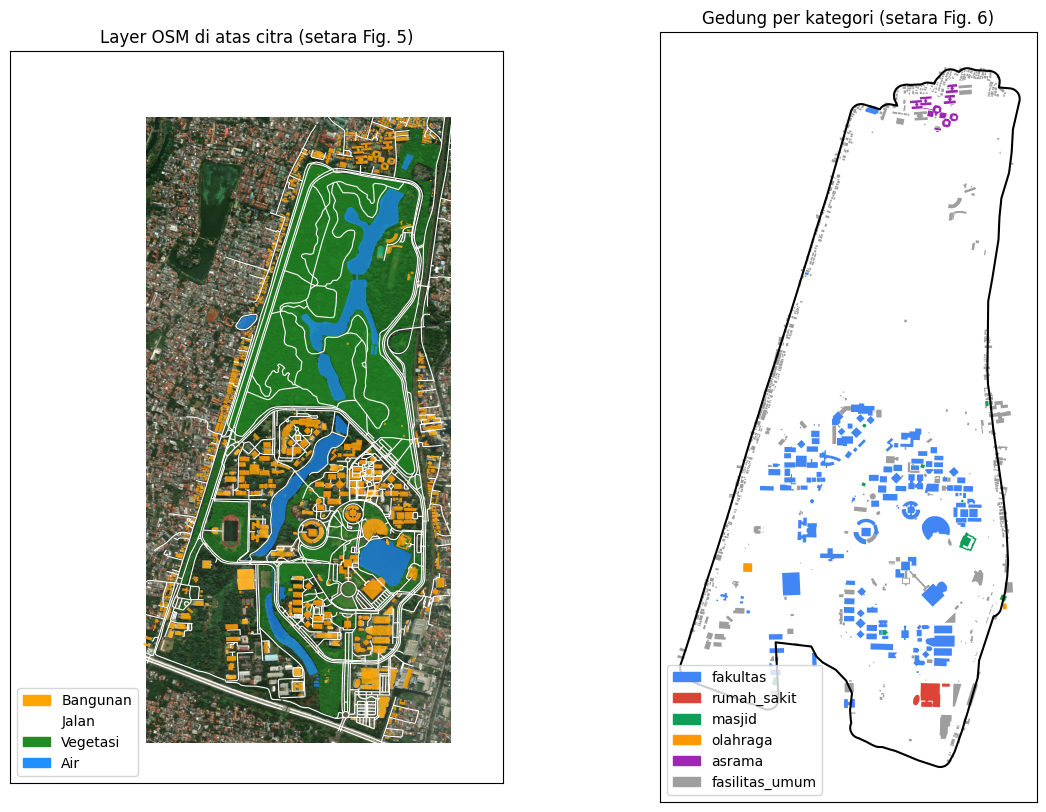

In [6]:
with rasterio.open(img_path) as src:
    f = max(1, src.width // 1500)
    img = src.read(out_shape=(3, src.height // f, src.width // f))
    img_tr = src.transform * src.transform.scale(src.width / img.shape[2], src.height / img.shape[1])

fig, ax = plt.subplots(1, 2, figsize=(14, 10))
show(img, transform=img_tr, ax=ax[0])
vegetation.plot(ax=ax[0], color="forestgreen", alpha=0.5)
water.plot(ax=ax[0], color="dodgerblue", alpha=0.7)
roads.plot(ax=ax[0], color="white", lw=0.8)
buildings.plot(ax=ax[0], color="orange", alpha=0.8)
ax[0].legend(handles=[Patch(color=c, label=l) for c, l in
                      [("orange", "Bangunan"), ("white", "Jalan"), ("forestgreen", "Vegetasi"), ("dodgerblue", "Air")]],
             loc="lower left")
ax[0].set_title("Layer OSM di atas citra (setara Fig. 5)")

aoi_buf.boundary.plot(ax=ax[1], color="k")
for cat, col in CATEGORY_COLORS.items():
    buildings[buildings.category == cat].plot(ax=ax[1], color=np.array(col) / 255)
ax[1].legend(handles=[Patch(color=np.array(c) / 255, label=k) for k, c in CATEGORY_COLORS.items()], loc="lower left")
ax[1].set_title("Gedung per kategori (setara Fig. 6)")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
savefig(fig, "fig05_06_tematik.png")
plt.show()

## 5. Verifikasi visual 25 gedung OSM

Periksa tiap panel: apakah garis kuning pas dengan atap/dasar gedung di citra?
Isi kolom `ok` (1 = sesuai, 0 = tidak) di `interim/verify_sample.csv`, lalu jalankan sel terakhir.

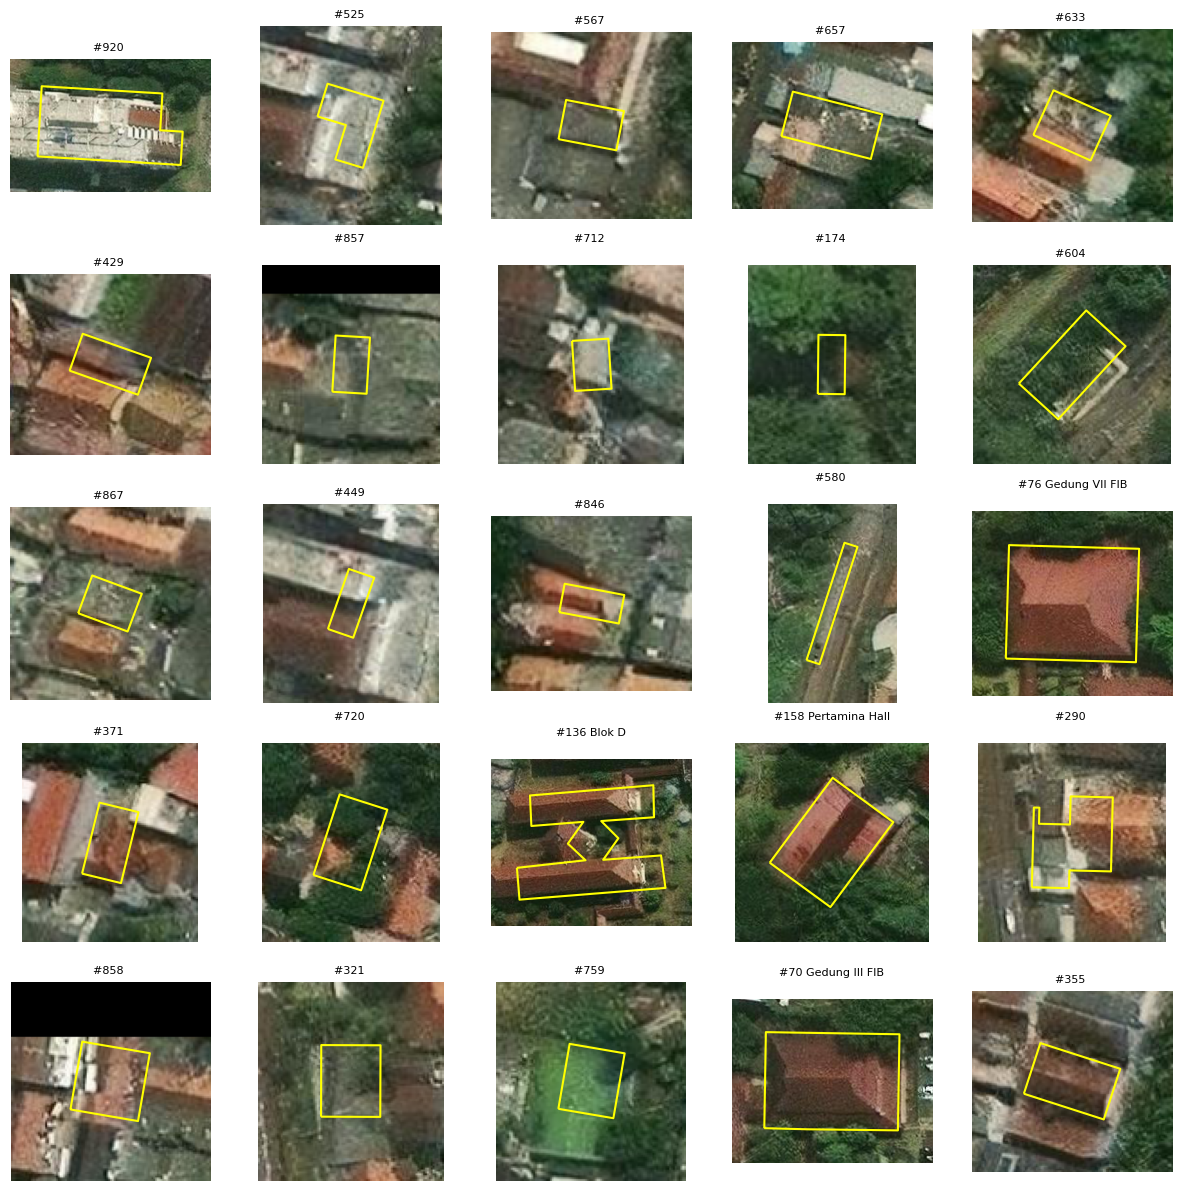

Isi kolom ok di /home/luwes-system/Desktop/bahan ajar 2026/ui3d/interim/verify_sample.csv


In [7]:
n = min(F["verify_sample"], len(buildings))
sample = buildings.sample(n, random_state=CFG["maskrcnn"]["seed"])
cols = 5
fig, axs = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(3 * cols, 3 * np.ceil(n / cols)))
with rasterio.open(img_path) as src:
    for a, (i, r) in zip(axs.ravel(), sample.iterrows()):
        x0, y0, x1, y1 = r.geometry.buffer(10).bounds
        win = rasterio.windows.from_bounds(x0, y0, x1, y1, src.transform)
        show(src.read(window=win, boundless=True), transform=src.window_transform(win), ax=a)
        gpd.GeoSeries([r.geometry]).boundary.plot(ax=a, color="yellow", lw=1.5)
        a.set_title(f"#{i} {str(r.get('name') or '')[:18]}", fontsize=8)
for a in axs.ravel():
    a.axis("off")
savefig(fig, "fig_verifikasi_osm.png")
plt.show()

vpath = interim("verify_sample.csv")
if not vpath.exists():
    pd.DataFrame({"idx": sample.index, "id": sample.get("id"), "name": sample.get("name"), "ok": ""}).to_csv(vpath, index=False)
print("Isi kolom ok di", vpath)

In [8]:
v = pd.read_csv(vpath)
if v.ok.notna().any():
    v = v.dropna(subset=["ok"])
    print(f"OSM sesuai citra: {int(v.ok.sum())}/{len(v)} ({v.ok.mean():.0%})")
else:
    print("verify_sample.csv belum diisi")

verify_sample.csv belum diisi
